In [1]:
# Import yfinance package
import yfinance as yf
import numpy as np

# For plotting
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid')

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

## Get Available Expiration Dates

In [2]:
# Create ticker object for Microsoft
msft = yf.Ticker('MSFT')

# Call the options on the ticker object to get the expiration dates
msft.options

('2026-08-14',
 '2026-08-17',
 '2026-08-19',
 '2026-08-21',
 '2026-08-28',
 '2026-09-04',
 '2026-09-11',
 '2026-09-18',
 '2026-09-25',
 '2026-10-16',
 '2026-11-20',
 '2026-12-18',
 '2027-01-15',
 '2027-03-19',
 '2027-06-17',
 '2027-09-17',
 '2027-12-17',
 '2028-01-21',
 '2028-06-16',
 '2028-12-15')

## Options Chain Data

In [3]:
# Get options chain for specific expiration date
option_chain = msft.option_chain(date=msft.options[0])

## Get Calls Data¶

In [4]:
# Get Microsoft calls options chain data
option_chain.calls.head()

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,MSFT260814C00270000,2026-08-07 19:44:18+00:00,270.0,231.65,0.0,0.0,0.0,0.0,1.0,1,0.00001,True,REGULAR,USD
1,MSFT260814C00300000,2026-08-11 13:49:40+00:00,300.0,200.75,0.0,0.0,0.0,0.0,1.0,10,0.00001,True,REGULAR,USD
2,MSFT260814C00305000,2026-07-30 13:49:25+00:00,305.0,146.60,0.0,0.0,0.0,0.0,1.0,15,0.00001,True,REGULAR,USD
3,MSFT260814C00310000,2026-07-27 13:39:30+00:00,310.0,82.48,0.0,0.0,0.0,0.0,5.0,13,0.00001,True,REGULAR,USD
4,MSFT260814C00315000,2026-07-30 19:55:03+00:00,315.0,137.15,0.0,0.0,0.0,0.0,1.0,27,0.00001,True,REGULAR,USD


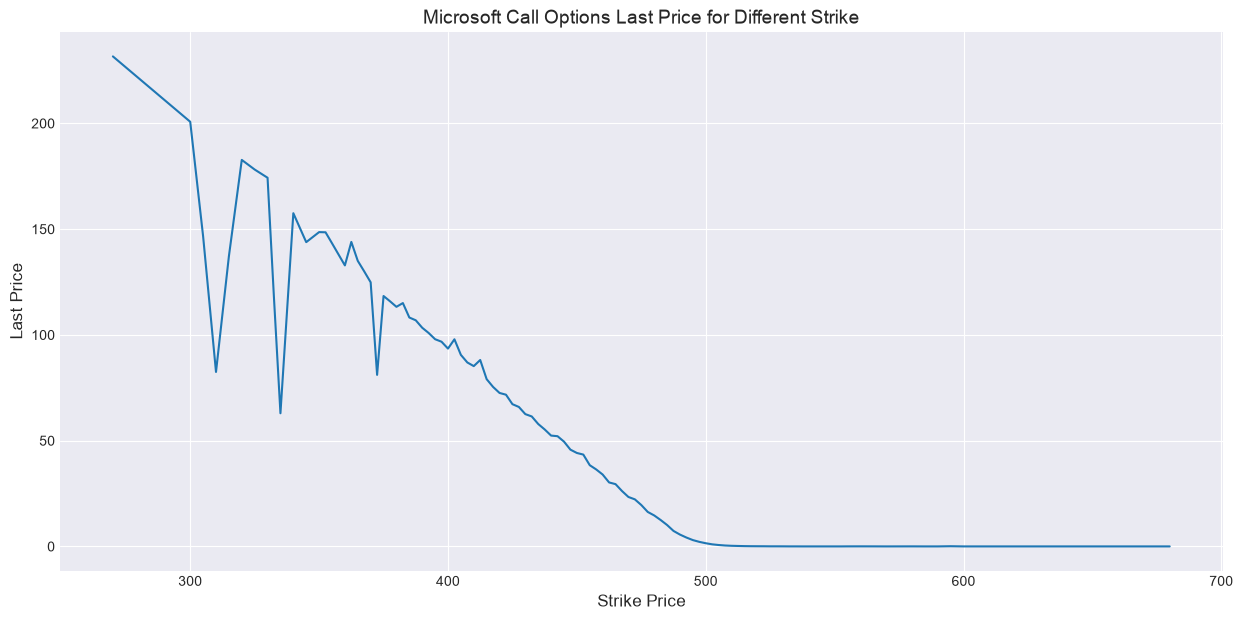

In [7]:
# Convert data to numpy arrays
call_strike_prices = np.array(option_chain.calls.strike)
call_last_prices = np.array(option_chain.calls.lastPrice)

# Plot call strike price vs call last traded price
plt.figure(figsize=(15, 7))
plt.plot(call_strike_prices, call_last_prices)
plt.xlabel('Strike Price', fontsize=12)
plt.ylabel('Last Price', fontsize=12)
plt.title('Microsoft Call Options Last Price for Different Strike', fontsize=14)
plt.show()

## Get Puts Data

In [8]:
# Get Microsoft puts options chain data
option_chain.puts.head()

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,MSFT260814P00270000,2026-08-07 18:17:12+00:00,270.0,0.01,0.0,0.0,0.0,0.0,1982,2293,0.500005,False,REGULAR,USD
1,MSFT260814P00280000,2026-08-07 19:08:05+00:00,280.0,0.01,0.0,0.0,0.0,0.0,604,664,0.500005,False,REGULAR,USD
2,MSFT260814P00290000,2026-08-10 14:50:01+00:00,290.0,0.01,0.0,0.0,0.0,0.0,1,52,0.500005,False,REGULAR,USD
3,MSFT260814P00300000,2026-08-07 13:56:45+00:00,300.0,0.06,0.0,0.0,0.0,0.0,1,189,0.500005,False,REGULAR,USD
4,MSFT260814P00305000,2026-08-03 16:31:36+00:00,305.0,0.05,0.0,0.0,0.0,0.0,2,71,0.500005,False,REGULAR,USD


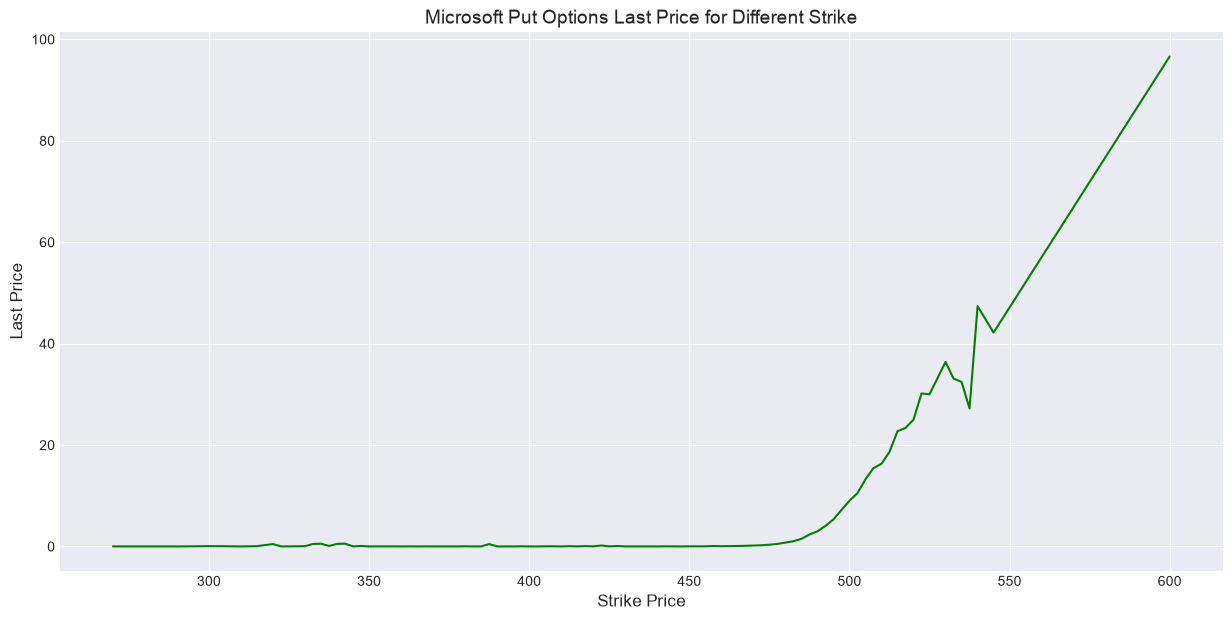

In [10]:
# Convert data to numpy arrays
put_strike_prices = np.array(option_chain.puts.strike)
put_last_prices = np.array(option_chain.puts.lastPrice)

# Plot put strike price vs put last traded price
plt.figure(figsize=(15, 7))
plt.plot(put_strike_prices, put_last_prices, color='g')
plt.xlabel('Strike Price', fontsize=12)
plt.ylabel('Last Price', fontsize=12)
plt.title('Microsoft Put Options Last Price for Different Strike', fontsize=14)
plt.show()